In [60]:
import sys

print("Python version:")
print(sys.version)

print("\nPython location:")
print(sys.executable)

Python version:
3.11.5 | packaged by Anaconda, Inc. | (main, Sep 11 2023, 13:26:23) [MSC v.1916 64 bit (AMD64)]

Python location:
C:\Users\praja\anaconda3\python.exe


In [61]:
import sys

!{sys.executable} -m pip install s3fs

In [62]:
import s3fs

print("✅ s3fs is installed!")
print("Version:", s3fs.__version__)

✅ s3fs is installed!
Version: 2024.12.0


In [63]:
import s3fs

fs = s3fs.S3FileSystem(anon=True)

print("✅ Connected to public AWS S3")

✅ Connected to public AWS S3


In [64]:
path = "gov-nasa-hdrl-data1/contrib/fdl-sdoml/"

files = fs.ls(path)

print("Number of items:", len(files))

for item in files[:20]:
    print(item)

Number of items: 2
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdml-sdomlv1


In [65]:
v2_path = "gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2"

v2_files = fs.ls(v2_path)

print("Number of items:", len(v2_files))

for item in v2_files[:30]:
    print(item)
    

Number of items: 7
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/.zgroup
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/notebooks
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/sdomlv2.zarr
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/sdomlv2_eve.zarr
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/sdomlv2_hmi.zarr
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/sdomlv2_hmi_small.zarr
gov-nasa-hdrl-data1/contrib/fdl-sdoml/fdl-sdoml-v2/sdomlv2_small.zarr


sdomlv2.zarr          ← full AIA dataset
sdomlv2_small.zarr   ← ⭐ smaller AIA dataset
sdomlv2_hmi.zarr      ← full HMI
sdomlv2_hmi_small.zarr ← ⭐ smaller HMI
sdomlv2_eve.zarr      ← EVE

In [67]:
import zarr

sdo_path = (
    "gov-nasa-hdrl-data1/"
    "contrib/fdl-sdoml/"
    "fdl-sdoml-v2/"
    "sdomlv2_small.zarr"
)

store = s3fs.S3Map(
    root=sdo_path,
    s3=fs,
    check=False
)

print("✅ SDO Zarr store connected!")

✅ SDO Zarr store connected!


In [68]:
root = zarr.open_group(store=store, mode="r")

print("✅ SDO dataset opened!")

✅ SDO dataset opened!


In [69]:
print(root.tree())

/
└── 2010
    ├── 131A (6135, 512, 512) float32
    ├── 1600A (6136, 512, 512) float32
    ├── 1700A (6135, 512, 512) float32
    ├── 171A (6135, 512, 512) float32
    ├── 193A (6135, 512, 512) float32
    ├── 211A (6136, 512, 512) float32
    ├── 304A (6134, 512, 512) float32
    ├── 335A (6135, 512, 512) float32
    └── 94A (6136, 512, 512) float32



In [70]:
aia171 = root["2010"]["171A"]

print("Shape:", aia171.shape)
print("Data type:", aia171.dtype)

Shape: (6135, 512, 512)
Data type: float32


In [71]:
image = aia171[0, :, :]

print("Image shape:", image.shape)
print("Data type:", image.dtype)

Image shape: (512, 512)
Data type: float32


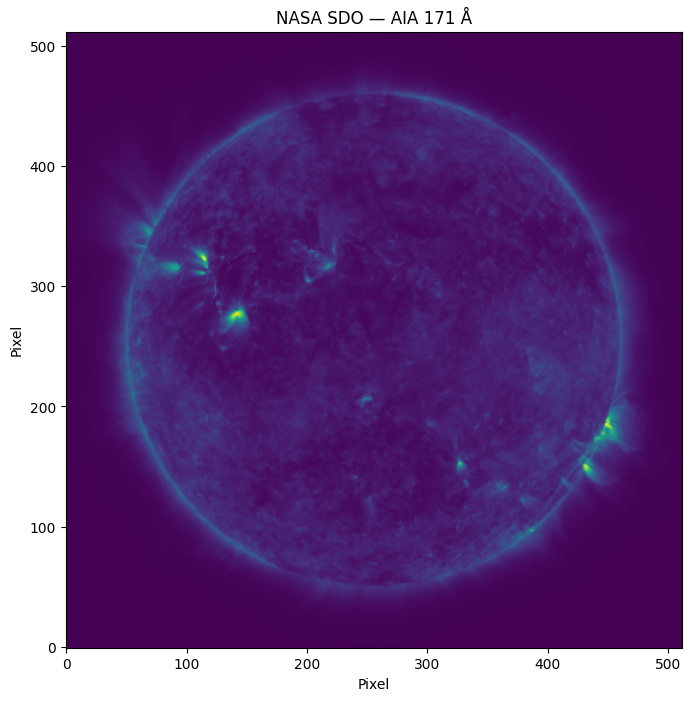

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))

plt.imshow(image, origin="lower")

plt.title("NASA SDO — AIA 171 Å")
plt.xlabel("Pixel")
plt.ylabel("Pixel")

plt.show()

In [73]:
import numpy as np
print("Minimum:", image.min())
print("Maximum:", image.max())
print("Mean:", image.mean())
print("Median:", np.median(image))

Minimum: 0.0
Maximum: 1882.851
Mean: 108.00937
Median: 85.96394


In [74]:
print("Number of pixels:", image.size)
print("NaN pixels:", np.isnan(image).sum())

Number of pixels: 262144
NaN pixels: 0


In [75]:
import numpy as np

In [76]:
print("Minimum intensity :", image.min())
print("Maximum intensity :", image.max())
print("Mean intensity    :", image.mean())
print("Median intensity  :", np.median(image))
print("Standard deviation:", image.std())

Minimum intensity : 0.0
Maximum intensity : 1882.851
Mean intensity    : 108.00937
Median intensity  : 85.96394
Standard deviation: 117.19743


In [77]:
print("Total pixels :", image.size)
print("NaN pixels   :", np.isnan(image).sum())
print("Infinite     :", np.isinf(image).sum())

Total pixels : 262144
NaN pixels   : 0
Infinite     : 0


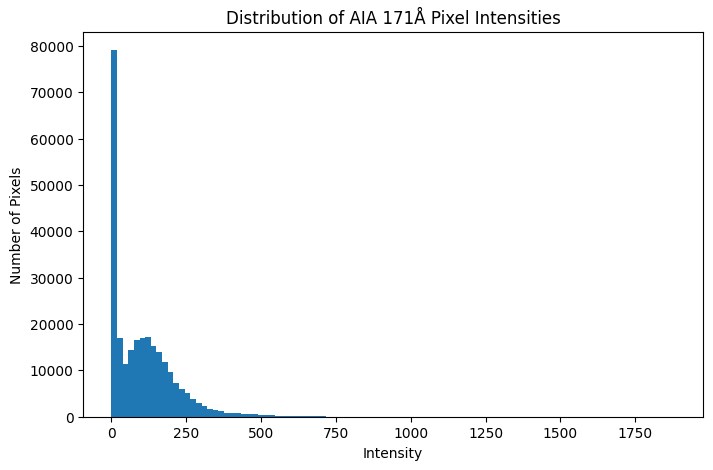

In [78]:
plt.figure(figsize=(8,5))

plt.hist(image.flatten(), bins=100)

plt.title("Distribution of AIA 171Å Pixel Intensities")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")

plt.show()

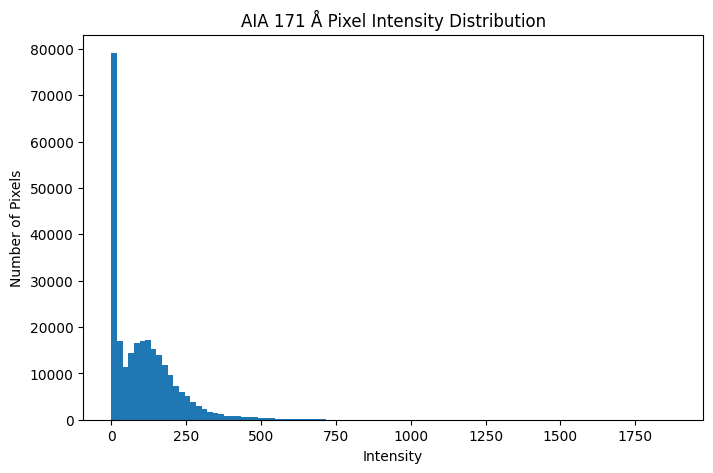

In [79]:
plt.figure(figsize=(8, 5))

plt.hist(image.flatten(), bins=100)

plt.title("AIA 171 Å Pixel Intensity Distribution")
plt.xlabel("Intensity")
plt.ylabel("Number of Pixels")

plt.show()

In [80]:
image_0 = aia171[0, :, :]
image_1000 = aia171[1000, :, :]

print("Image 0 mean:", image_0.mean())
print("Image 1000 mean:", image_1000.mean())

Image 0 mean: 108.00937
Image 1000 mean: 115.41384


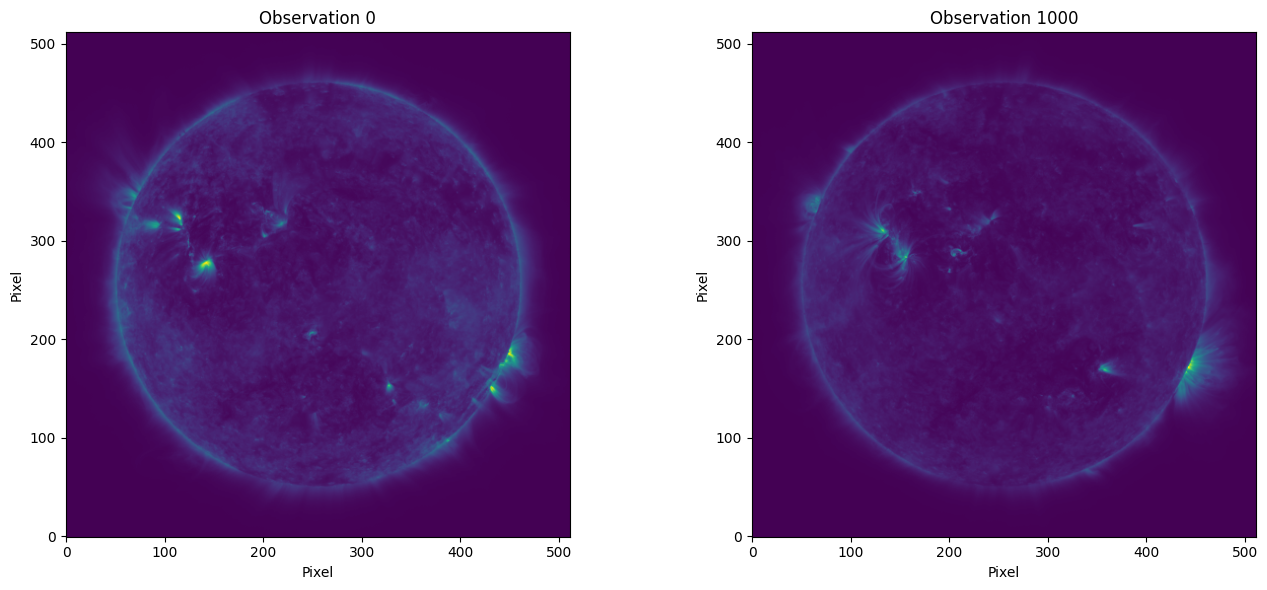

In [81]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(image_0, origin="lower")
axes[0].set_title("Observation 0")
axes[0].set_xlabel("Pixel")
axes[0].set_ylabel("Pixel")

axes[1].imshow(image_1000, origin="lower")
axes[1].set_title("Observation 1000")
axes[1].set_xlabel("Pixel")
axes[1].set_ylabel("Pixel")

plt.tight_layout()
plt.show()

In [82]:
difference = image_1000 - image_0

print("Mean difference:", difference.mean())
print("Maximum increase:", difference.max())
print("Maximum decrease:", difference.min())
print("Mean absolute difference:", np.abs(difference).mean())

Mean difference: 7.4044724
Maximum increase: 2285.1382
Maximum decrease: -1664.6831
Mean absolute difference: 43.207848


In [83]:
np.abs(difference).mean()

np.float32(43.207848)

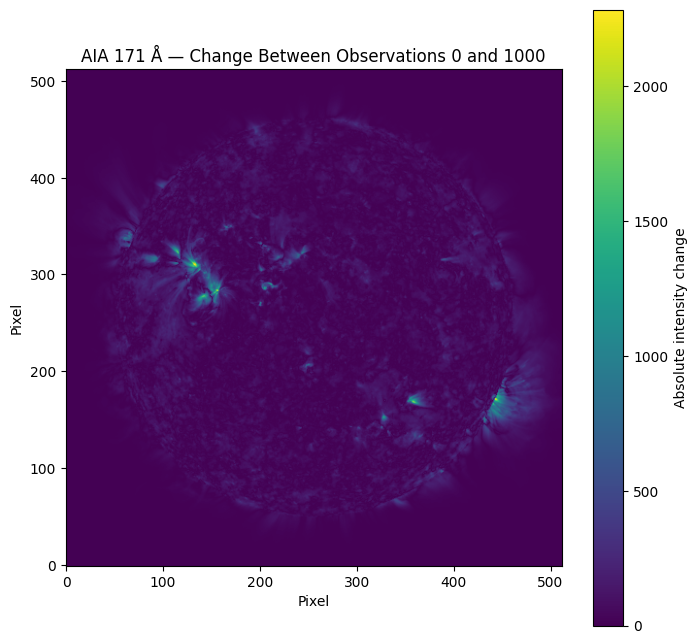

In [84]:
plt.figure(figsize=(8, 8))

plt.imshow(
    np.abs(difference),
    origin="lower"
)

plt.colorbar(label="Absolute intensity change")
plt.title("AIA 171 Å — Change Between Observations 0 and 1000")
plt.xlabel("Pixel")
plt.ylabel("Pixel")

plt.show()

In [85]:
abs_difference = np.abs(difference)

threshold = np.percentile(abs_difference, 99)

print("99th percentile change:", threshold)
print("Pixels above threshold:", np.sum(abs_difference > threshold))
print("Total pixels:", abs_difference.size)

99th percentile change: 371.81644
Pixels above threshold: 2622
Total pixels: 262144


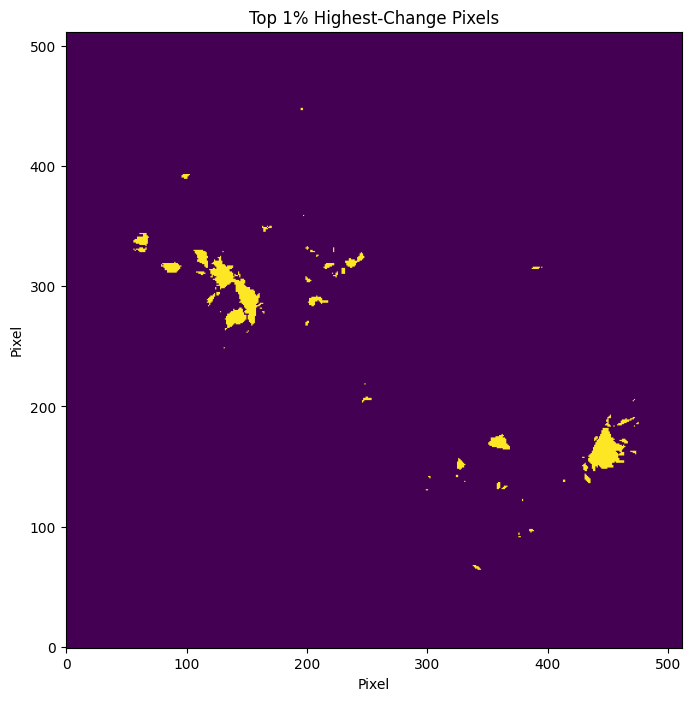

In [86]:
mask = abs_difference > threshold

plt.figure(figsize=(8, 8))

plt.imshow(mask, origin="lower")

plt.title("Top 1% Highest-Change Pixels")
plt.xlabel("Pixel")
plt.ylabel("Pixel")

plt.show()

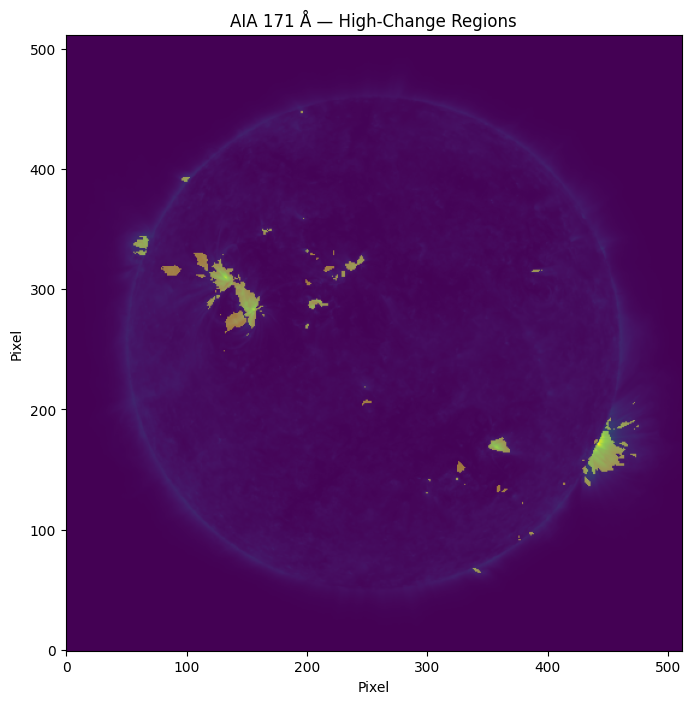

In [87]:
plt.figure(figsize=(8, 8))

plt.imshow(image_1000, origin="lower")
plt.imshow(
    mask,
    origin="lower",
    alpha=0.5
)

plt.title("AIA 171 Å — High-Change Regions")
plt.xlabel("Pixel")
plt.ylabel("Pixel")

plt.show()

In [120]:
high_change_pixels = np.sum(mask)
total_pixels = mask.size

activity_percentage = (high_change_pixels / total_pixels) * 100

print("High-change pixels:", high_change_pixels)
print("Total pixels:", total_pixels)
print("High-change percentage:", activity_percentage, "%")

High-change pixels: 2622
Total pixels: 262144
High-change percentage: 1.000213623046875 %


In [122]:
activity_scores = []

# Only 5 observations for a quick test
indices = [1, 100, 500, 1000, 2000]

for i in indices:
    current = np.array(aia171[i, :, :])
    previous = np.array(aia171[i - 1, :, :])

    change = np.abs(current - previous)

    threshold = np.percentile(change, 99)

    score = np.mean(change > threshold) * 100

    activity_scores.append(score)

    print(f"Observation {i}: {score:.4f}%")

Observation 1: 1.0002%
Observation 100: 1.0002%
Observation 500: 1.0002%
Observation 1000: 1.0002%
Observation 2000: 1.0002%


In [124]:
activity_scores = []

indices = [1, 100, 500, 1000, 2000]

for i in indices:
    current = np.array(aia171[i, ::4, ::4])
    previous = np.array(aia171[i - 1, ::4, ::4])

    change = np.abs(current - previous)

    # Average pixel change
    score = np.mean(change)

    activity_scores.append(score)

    print(f"Observation {i}: Mean change = {score:.4f}")

Observation 1: Mean change = 3.3497
Observation 100: Mean change = 3.4612
Observation 500: Mean change = 4.0114
Observation 1000: Mean change = 3.7112
Observation 2000: Mean change = 3.3637


In [126]:
scores = np.array(activity_scores)

max_index = np.argmax(scores)
max_score = scores[max_index]

print("Strongest activity:")
print("Observation:", indices[max_index])
print("Mean change:", max_score)

# Find top 3
top_3 = np.argsort(scores)[-3:][::-1]

print("\nTop activity observations:")

for idx in top_3:
    print(
        f"Observation {indices[idx]}: "
        f"{scores[idx]:.4f}"
    )

Strongest activity:
Observation: 500
Mean change: 4.0113745

Top activity observations:
Observation 500: 4.0114
Observation 1000: 3.7112
Observation 100: 3.4612


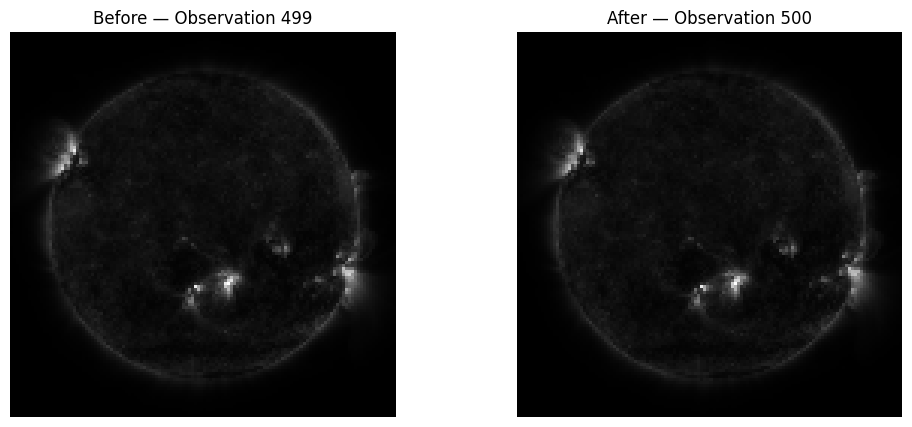

In [128]:
strongest_i = indices[max_index]

previous_image = np.array(aia171[strongest_i - 1, ::4, ::4])
current_image = np.array(aia171[strongest_i, ::4, ::4])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(previous_image, cmap="gray")
plt.title(f"Before — Observation {strongest_i - 1}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(current_image, cmap="gray")
plt.title(f"After — Observation {strongest_i}")
plt.axis("off")

plt.show()

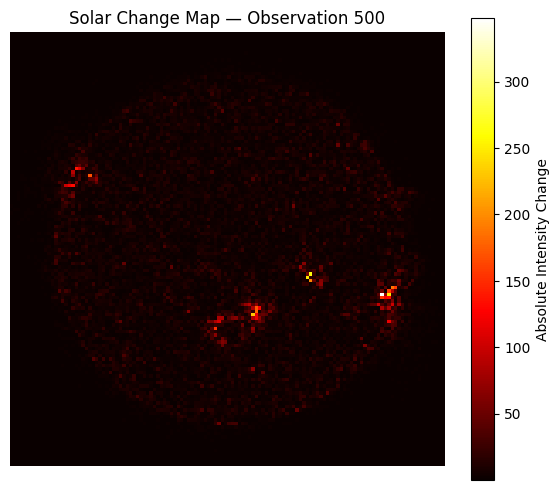

In [130]:
change_map = np.abs(current_image - previous_image)

plt.figure(figsize=(7, 6))

plt.imshow(change_map, cmap="hot")

plt.colorbar(label="Absolute Intensity Change")

plt.title(
    f"Solar Change Map — Observation {strongest_i}"
)

plt.axis("off")

plt.show()

In [132]:
# Find location of maximum change
max_position = np.unravel_index(
    np.argmax(change_map),
    change_map.shape
)

y, x = max_position

max_change = change_map[y, x]

print("Strongest changing pixel:")
print("X position:", x)
print("Y position:", y)
print("Maximum change:", max_change)

Strongest changing pixel:
X position: 109
Y position: 77
Maximum change: 347.89777


In [134]:
# Set threshold at the 99th percentile
threshold = np.percentile(change_map, 99)

# Create binary activity mask
activity_mask = change_map > threshold

# Count active pixels
active_pixels = np.sum(activity_mask)

total_pixels = activity_mask.size

percentage = (active_pixels / total_pixels) * 100

print("Activity threshold:", threshold)
print("High-change pixels:", active_pixels)
print("Total pixels:", total_pixels)
print("High-change area:", f"{percentage:.2f}%")

Activity threshold: 32.470238
High-change pixels: 164
Total pixels: 16384
High-change area: 1.00%
